<!-- **Notes on Python virtual environment**

To activate the virtual environment, fix Windows bug then activate:
1. `Set-ExecutionPolicy Unrestricted -Scope Process`
2. `.venv\Scripts\activate` -->

Implementation of a (robust) power system estimation problem, solving with distributed optimisation algorithms.
Based on problem formulation of Kekatos & Giannakis (2012) and using problem data from Korres (2011)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from algorithms import pgextra, nids, gf_pgextra
import pickle

In [ ]:
# Resolvent - soft thresholding operator
def soft_threshold(z, s):
    return np.sign(z) * np.clip(np.abs(z) - s, a_min=0, a_max=None) # Using numpy array broadcasting

def JA(z, step, data):
    r"""
    Soft-thresholding operator for yi: sgn(z[i])*max(abs(z[i])-\tau \lambda[i]), 0)
    :param z: n*(2*n+\sum d_i)-length array, where z[i] = [x, y]. x is (2*n)-array of states, y is (\sum d_i)-array of bad data indicators
    """
    n = z.shape[0]  # no. of agents
    mi_csum = np.cumsum([0]+[len(data['m'][ii]) for ii in range(n)])   # cumulative no. of measurements for each agent
    p = z.shape[1] - mi_csum[-1]   # no. of state vars

    JAz = z.copy()
    for ii in range(n):
        yii = z[ii, p+mi_csum[ii]:p+mi_csum[ii+1]].flatten() # agent local copy of states, agent-specific bad data indicators
        lambda_i = data['lambda'][ii]   # regularisation parameter
        JAz[ii,p+mi_csum[ii]:p+mi_csum[ii+1]] = soft_threshold(yii, step*lambda_i) # only threshold yii

        # # TODO alternative model: soft-threshold all of yi
        # yi = z[ii, p:].flatten() # agent local copy of states, agent-specific bad data indicators
        # lambda_i = data['lambda'][ii]   # regularisation parameter
        # JAz[ii,p:] = soft_threshold(yi, step*lambda_i)
    
    return JAz  # return other values as inputted

def B(z, data):
    r"""
    Evaulate gradient operator (B(z))_i = -[Hi^T, I]@(mi - Hi@xi - oi), 
    """
    n = z.shape[0]  # no. of agents
    mi_csum = np.cumsum([0]+[len(data['m'][ii]) for ii in range(n)])   # cumulative no. of measurements for each agent
    p = z.shape[1] - mi_csum[-1]   # no. of state vars
    Bz = np.zeros(z.shape)

    for ii in range(n):
        zi = z[ii].flatten()
        xi, yii = zi[:p], zi[p+mi_csum[ii]:p+mi_csum[ii+1]] # agent local copy of states, agent-specific bad data indicators
        Hi = data['H'][ii]  # Measurement matrix
        mi = data['m'][ii]  # Measurements

        Bz[ii,:p] = -Hi.T@(mi - Hi@xi - yii)
        Bz[ii,p+mi_csum[ii]:p+mi_csum[ii+1]] = -(mi - Hi@xi - yii)
        
    return Bz

In [3]:
rng_gen = np.random.default_rng(2026)
nagents = 4
dim = 14 # no. of state variables (here it is buses)

with open(r'C:\Users\TIMMSLF\OneDrive - The University of Melbourne\Documents\PhD\Code\Data_fast_pgextra\dict_of_psse_instances', 'rb') as f:
    datadict = pickle.load(f)
datadict = datadict[0]

# # Objective function parameters
# H = { # Initialise measurement matrices
#     0: np.zeros((5, dim)),
#     1: np.zeros((4, dim)),
#     2: np.zeros((6, dim)),
#     3: np.zeros((3, dim))
# }
# # Fill in non-zero entries measurement matrices
# H[0][:,0] = [1., 1., 1., 0., 2.]    # bus 1
# H[0][:,1] = [0., -1., 0., 1., -1.]  # bus 2
# H[0][:,4] = [0., 0., -1., -1., -1.]  # bus 5

# H[1][:,2] = [1., 1., 0., 0.]   # bus 3
# H[1][:,3] = [0., -1., 1., 0.]  # bus 4
# H[1][:,6] = [0., 0., -1., 1.]  # bus 7
# H[1][:,7] = [0., 0., 0., -1.]  # bus 8

# H[2][:,5]  = [1., 1., 1., 1., 0., -1.]   # bus 6
# H[2][:,10] = [0., -1., 0., 0., 0., 0.]   # bus 11
# H[2][:,11] = [0., 0., -1., 0., 1., 2.]   # bus 12
# H[2][:,12] = [0., 0., 0., -1., -1., -1.] # bus 13

# H[3][:,8]  = [1., 1., 1.]   # bus 9
# H[3][:,9]  = [0., -1., 0.]  # bus 10
# H[3][:,13] = [0., 0., -1.]  # bus 14

# m = { # measurements
#     0: np.array([0., 0.0869, 0.3532, 0.663, 0.2402]),   # 3rd measurement is "bad"
#     1: np.array([0., -0.0243, 0.0356, -0.0002]),
#     2: np.array([0., 0.0099, 0.0148, 0.0164, 0.0016, -0.0133]),
#     3: np.array([0., 0.028, 0.0192])
# }
# lambda_vec = 0.5*np.ones(nagents) # Regularisation parameters

# datadict = {'H': H, 'm': m, 'lambda': lambda_vec}

In [4]:
# Algorithm parameters
# Graph from partitioning of IEEE 14-bus test case
edges = [(0,1),
         (1,2),
         (2,3)]
G = nx.Graph(edges)

# Metropolis constant edge weight matrix
W = np.zeros((nagents, nagents))
for i,j in edges:
    W[i,j] = 1./(max(G.degree[i], G.degree[j])+1.) # w_ij = 1/(max{d_i, d_j}+\eps) for i,j\in Edges
    W[j, i] = W[i,j]
for i in range(nagents):
    W[i,i] = 1. - np.sum(W[i,:])    # w_ii = 1 - \sum_{j\in Edges} w_ij


# Step size
Hi_norms = np.array([np.linalg.norm(datadict['H'][ii], ord=2)**2 for ii in datadict['H']]) # norms of matrices Hi
L = np.max([(Hi_norms + 1)*np.clip(Hi_norms, a_min=1, a_max=None)]) # max{(|Hi|**2+1)*max{|Hi|**2,1}}
tau = 0.9 * (1 + np.min(np.linalg.eigvalsh(W))) / L  # tau <= (1-||K||^2)/L

# Other algorithm parameters
thetainv = 2. - tau*L/(1 + np.min(np.linalg.eigvalsh(W)))   # 1/averaged constant of Condat-Vu operator
s = 0.9* thetainv # 0 < s < (4\beta_M-1)/(2\beta_M) # parameter for Fast PG-EXTRA
alpha = 5.  # parameter for Fast PG-EXTRA
beta = 0.9/np.linalg.norm(tau*0.5*(np.eye(nagents)-W), ord=2)   # parameter for NIDS, \beta = 0.9/||tau^(1/2)*((I-W)/2)*tau^(1/2))||
maxit = 10000

def alpha_k(k):
    r"""
    Linear cooling heuristic: alpha(k) increasing linearly to 100*\alpha at maxit/2 iterations. 
    \alpha_max = 100*\alpha
    :param: k: iteration number
    """
    if k<= (maxit//2):
        ak = alpha + 99*alpha*k/(maxit//2)
    else:
        ak = 100*alpha
    return ak

def sigma_k(k):
    return alpha_k(k)

In [5]:
measures = sum(len(datadict['m'][ii]) for ii in datadict['m'])
x0 = np.zeros((nagents, dim+measures)) # state variables + 1 bad data variable per measurement

# Run PG-EXTRA, NIDS, and (normal) Fast PG-EXTRA
params = {'tau': tau, 'W': W, 'maxit': maxit}
zsol1, res_pg, rel_pg, con_pg = pgextra(x0, JA, B, params, data=datadict)
print()
params = {'tau': tau, 'beta': beta, 'W': W, 'maxit': maxit}
zsol2, res_nids, rel_nids, con_nids = nids(x0, JA, B, params, data=datadict)

# Initialise parameters & errors for Fast PG-EXTRA
etas = [0.1, 0.5, 0.8, 0.95, 1.0]
num_params = len(etas)

res_gfpg = np.zeros((num_params, maxit))
rel_gfpg = np.zeros((num_params, maxit))
con_gfpg = np.zeros((num_params, maxit))

# Run Generalised Fast PG-EXTRA for different etas and linear cooling alpha(k)
for ii in range(num_params):
    params = {'tau': tau,'s': s,'alpha': alpha_k,'sigma': sigma_k,'eta': etas[ii], 'W': W, 'maxit': maxit}
    print(f'\neta={etas[ii]:.2f}',end='\n')
    _, res_gfpg[ii,:], rel_gfpg[ii,:], con_gfpg[ii,:] = gf_pgextra(x0, JA, B, params, data=datadict)
print('')

# Run Generalised Fast PG-EXTRA with alpha(k)=500
params = {'tau': tau, 's': s, 'alpha': lambda k: 500., 'sigma': lambda k: 500., 'eta': 1.0, 'W': W, 'maxit': maxit}
_, res_gfpg500, rel_gfpg500, con_gfpg500 = gf_pgextra(x0, JA, B, params, data=datadict)


PG-EXTRA: iteration 10000 of 10000
NIDS: iteration 10000 of 10000
eta=0.10
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=0.50
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=0.80
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=0.95
Gen. Fast PG-EXTRA: iteration 10000 of 10000
eta=1.00
Gen. Fast PG-EXTRA: iteration 10000 of 10000


In [6]:
print(f'# state variables: {dim}')  # no. of states
print(f'# fault variables: {zsol1.shape[1]-dim}')   # no. of fault indicators
print(f'# av. faults present: {np.mean([np.count_nonzero(zsol1[ii,dim:]) for ii in range(nagents)])}') # nonzero fault indicators = fault present
# print(zsol1[0])

# state variables: 14
# fault variables: 18
# av. faults present: 0.0


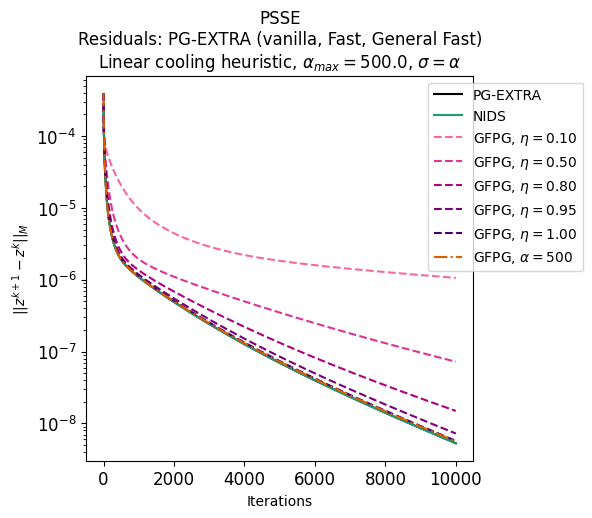

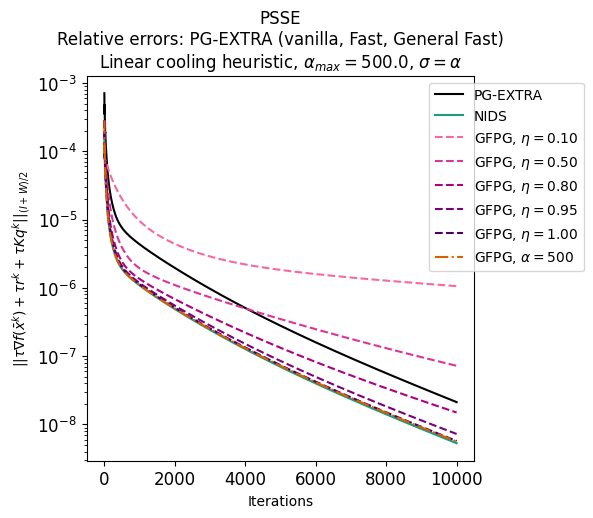

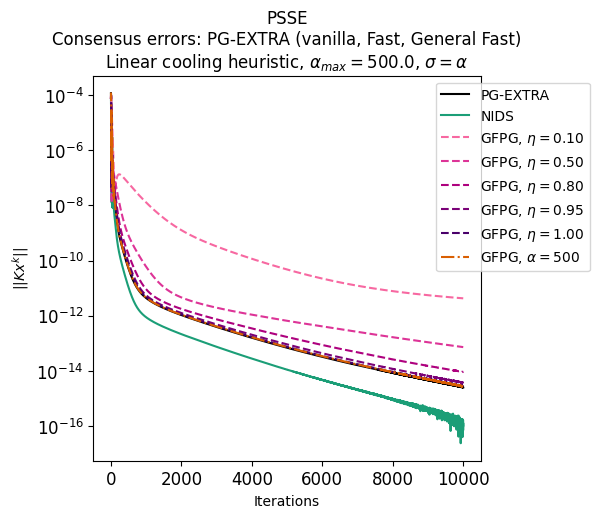

In [7]:
# 5-class sequential
colour = {'pg': 'k', 'nids': '#1b9e77', '500': '#d95f02', '1000': 'r', 0: '#f768a1', 1: '#dd3497', 2: '#ae017e', 3: '#7a0177', 4: '#49006a'}

fig_res = plt.figure(figsize=(5, 5))
ax_res = fig_res.add_subplot(111)
scale_k = 1e-2
ax_res.semilogy(res_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_res.semilogy(res_nids, color=colour['nids'], linestyle='-', label=r'NIDS')
for ii in range(num_params):
    ax_res.semilogy(res_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_res.semilogy(res_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
ax_res.set_xlabel("Iterations")
ax_res.set_ylabel("$||z^{k+1}-z^k||_M$")
ax_res.set_title(f"PSSE\nResiduals: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_res.tick_params(axis='both', which='both', labelsize=12)
ax_res.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

scale_k = 1e-5
fig_rel = plt.figure(figsize=(5, 5))
ax_rel = fig_rel.add_subplot(111)
ax_rel.semilogy(rel_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_rel.semilogy(rel_nids, color=colour['nids'], linestyle='-', label=r'NIDS')
for ii in range(num_params):
    ax_rel.semilogy(rel_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_rel.semilogy(rel_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
ax_rel.set_xlabel("Iterations")
ax_rel.set_ylabel(r"$||\tau \nabla f(\bar{x}^k)+\tau r^k+\tau Kq^k||_{(I+W)/2}$")
ax_rel.set_title(f"PSSE\nRelative errors: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_rel.tick_params(axis='both', which='both', labelsize=12)
ax_rel.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

scale_k = 1e-2
scale_k2 = 1e-2
fig_con = plt.figure(figsize=(5, 5))
ax_con = fig_con.add_subplot(111)
ax_con.semilogy(con_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_con.semilogy(con_nids, color=colour['nids'], linestyle='-', label=r'NIDS')
for ii in range(num_params):
    ax_con.semilogy(con_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_con.semilogy(con_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
ax_con.set_xlabel("Iterations")
ax_con.set_ylabel(r"$||Kx^k||$")
ax_con.set_title(f"PSSE\nConsensus errors: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_con.tick_params(axis='both', which='both', labelsize=12)
ax_con.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

# filepath = r'C:\\Users\\TIMMSLF\\OneDrive - The University of Melbourne\\Documents\\PhD\\Code\\'
# fig_res.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_psse_res.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_rel.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_psse_rel.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_con.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_psse_con.pdf', bbox_inches='tight', pad_inches=0.2)